# Đề tài 26 — Nhận dạng thực thể tiếng Việt về COVID-19 (PhoNER_COVID19)
## Phần (A) Baseline CRF và (B) Zero-shot NER

**Môn:** Xử lý Ngôn ngữ Tự nhiên (XLNNTN) — HK1 2026-2027
**Phụ trách phần này:** Phúc (baseline + zero-shot)

**Bài báo gốc:** Truong, Dao, Nguyen, *"COVID-19 Named Entity Recognition for Vietnamese"*, NAACL 2021.
**Dataset:** PhoNER_COVID19 (VinAI Research), chỉ dùng cho mục đích học tập.

### Yêu cầu của giảng viên cho đề tài 26
1. **Tiền xử lý tách từ tiếng Việt** (`underthesea` / `VnCoreNLP`).
2. **(A) Baseline = CRF với đặc trưng từ** (`sklearn-crfsuite`).
3. **(B) Zero-shot = model NER tiếng Việt pretrained có sẵn** trên Hugging Face, dùng trực tiếp qua `pipeline`, **không train lại**, áp cho 10 loại thực thể đặc thù.
4. **Đánh giá: F1 theo từng loại thực thể** bằng `seqeval`.
5. **Phân tích lỗi** trên thực thể đặc thù (số ca bệnh `PATIENT_ID`, tên tổ chức y tế `ORGANIZATION`).
6. Giải thích vì sao zero-shot dự kiến sẽ yếu (model tổng quát không có các loại thực thể đặc thù).

### Mục lục
Giới thiệu bài báo nền tảng và bộ dữ liệu
0. Cài đặt thư viện và đọc dữ liệu
1. Khám phá dữ liệu
2. Tiền xử lý: tách từ tiếng Việt
3. (A) Baseline CRF
4. Phân tích lỗi CRF
5. (B) Zero-shot NER
6. So sánh CRF và zero-shot
7. Tóm tắt tiền xử lý và tham số đã dùng
8. Kết luận và ghi chú vấn đáp

## Giới thiệu bài báo nền tảng và bộ dữ liệu

**Bài báo:** T. H. Truong, M. H. Dao, D. Q. Nguyen (VinAI Research), *"COVID-19 Named Entity Recognition for Vietnamese"*, NAACL 2021.

**Vấn đề bài báo giải quyết.** Trước đó, dữ liệu NER tiếng Việt công khai chỉ có VLSP 2016 và VLSP 2018, mà hai bộ này chỉ gán 3 loại thực thể chung (tên người, tổ chức, địa điểm) nên khó dùng để trích thông tin về các ca bệnh COVID-19. Phần lớn các corpus về COVID-19 trên thế giới cũng chỉ có tiếng Anh.

**Đóng góp chính.**
1. Xây dựng bộ dữ liệu NER tiếng Việt đầu tiên về COVID-19 được gán nhãn thủ công, gồm 10 loại thực thể liên quan đến bệnh nhân (định nghĩa đủ tổng quát để dùng lại cho các dịch bệnh sau này). Bộ có khoảng 35 nghìn thực thể trên hơn 10 nghìn câu, nhiều thực thể nhất trong các bộ NER tiếng Việt vào thời điểm đó.
2. Chạy thử các mô hình nền: BiLSTM-CNN-CRF, XLM-R và PhoBERT. Hai kết luận chính: (i) tách từ tự động giúp cải thiện kết quả NER; (ii) fine-tune mô hình ngôn ngữ pretrained cho kết quả cao nhất, trong đó PhoBERT (đơn ngữ) tốt hơn XLM-R (đa ngữ).

**Nguồn và cách xây dựng dữ liệu.** Bài báo thu thập các bài gắn thẻ COVID-19 từ VnExpress, ZingNews, BaoMoi, ThanhNien (tháng 2 đến tháng 8/2020), tách câu bằng RDRSegmenter (VnCoreNLP), chọn câu nói về bệnh nhân ở Việt Nam bằng BM25Plus rồi lọc tay, được 10027 câu. Việc gán nhãn làm thủ công trên văn bản mức **âm tiết**; bản mức **từ** được tạo bằng cách chạy RDRSegmenter tự động (không làm đổi ranh giới thực thể gold). Hai người gán nhãn độc lập trên tập thử 1000 câu có độ đồng thuận F1 = 0,88 ở mức span.

**Cách chia tập.** Chia ngẫu nhiên theo tỉ lệ 5/2/3 và giữ phân bố loại thực thể giữa ba tập tương đương nhau: train 5027 / dev 2000 / test 3000 câu (15767 / 7478 / 11735 thực thể). Số liệu này khớp với số mình tự đếm ở mục 1. (Bảng thống kê trong bài báo ghi tổng 34984 thực thể, nhưng cộng các dòng loại thực thể lại ra 34980, đúng bằng số tự đếm.)

**Tên nhãn trong bài báo và trong file dữ liệu:** PERSON_NAME → `NAME`, OCCUPATION → `JOB`, SYMPTOM&DISEASE → `SYMPTOM_AND_DISEASE`; các nhãn còn lại giữ nguyên.

**Số liệu tham chiếu trong bài báo** (tập test, trung bình 5 lần chạy; F1 mức thực thể, đúng cả loại và ranh giới, cùng kiểu đánh giá với `seqeval`). Đây là mốc để đối chiếu, không phải kết quả do nhóm tự chạy:

| Mô hình trong bài báo | Micro-F1 |
|---|---|
| BiLSTM-CNN-CRF, mức âm tiết | 0,906 |
| BiLSTM-CNN-CRF, mức từ | 0,910 |
| PhoBERT-base, mức từ | 0,942 |
| PhoBERT-large, mức từ | 0,945 |

**Mục tiêu đề tài 26 và phần mình làm.** So sánh ba cách tiếp cận trên PhoNER_COVID19: (A) CRF với đặc trưng thủ công, (B) model NER tiếng Việt tổng quát dùng thẳng, không train lại (zero-shot), (C) fine-tune các mô hình pretrained (PhoBERT và hai kiến trúc khác) do các bạn còn lại phụ trách. Notebook này làm (A) và (B), kèm tiền xử lý tách từ, đánh giá F1 từng loại bằng `seqeval` và phân tích lỗi; kết quả dùng làm mốc cho phần fine-tune.

## 0. Cài đặt thư viện và đọc dữ liệu

- `sklearn-crfsuite`: thư viện CRF (Conditional Random Field) dùng giao diện giống scikit-learn.
- `seqeval`: tính Precision / Recall / F1 **theo thực thể** (entity-level) cho bài toán gán nhãn chuỗi BIO.
- `underthesea`: thư viện xử lý tiếng Việt, dùng để tách từ.
- `transformers`: để tải model NER pretrained từ Hugging Face cho phần zero-shot.

In [12]:
# Chạy 1 lần để cài thư viện (trên Colab hoặc máy cá nhân)
# torch: thư viện deep learning mà transformers cần để chạy model zero-shot
# (Colab có sẵn torch; chạy trên máy cá nhân thì phải cài thêm)
#%pip install -q sklearn-crfsuite seqeval underthesea transformers torch

In [13]:
import json
import os
import time
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt

import sklearn_crfsuite
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from seqeval.metrics.sequence_labeling import get_entities

### Đường dẫn tới dữ liệu

Dữ liệu nằm trong thư mục `data/` của repo (cách tải xem `data/README.md`), gồm 2 phiên bản:
- `data/word/` : văn bản **đã tách từ** (từ ghép nối bằng dấu `_`, ví dụ `bệnh_viện`).
- `data/syllable/` : văn bản tách theo **âm tiết** (mỗi tiếng là 1 token, ví dụ `bệnh`, `viện`).

Mỗi split có `train`, `dev`, `test`. Mỗi dòng trong file `.json` là 1 câu: `{"words": [...], "tags": [...]}`.

**Cách chạy:**
- **Trên máy:** mở notebook từ thư mục `notebooks/` của repo → giữ nguyên `DATA_DIR = "../data"`; kết quả ghi vào `results/` và `results/phan_tich/`.
- **Trên Colab:** mount Google Drive rồi sửa `DATA_DIR`, `KET_QUA_DIR` ở ô bên dưới (và `sys.path`, `THU_MUC_RESULTS` ở mục 6.1) thành đường dẫn trên Drive. Nên lưu kết quả vào Drive vì thư mục tạm của Colab bị xoá khi hết phiên.

In [ ]:
# Mặc định: chạy trên máy cá nhân.
# Notebook nằm trong notebooks/ nên "../" là thư mục gốc repo.
DATA_DIR = "../data"                      # data/word, data/syllable (xem data/README.md)
KET_QUA_DIR = "../results/phan_tich"      # nơi lưu model, bảng kết quả, dự đoán

print("Các file trong thư mục word:", os.listdir(os.path.join(DATA_DIR, "word")))

Các file trong thư mục word: ['dev_word.conll', 'dev_word.json', 'test_word.conll', 'test_word.json', 'train_word.conll', 'train_word.json']


In [15]:
def doc_file_json(duong_dan):
    """Đọc 1 file .json của PhoNER_COVID19.
    Mỗi dòng là 1 câu dạng {"words": [...], "tags": [...]}.
    Trả về 2 list: danh sách câu (list các từ) và danh sách nhãn."""
    cac_cau = []
    cac_nhan = []
    with open(duong_dan, encoding="utf-8") as f:
        for dong in f:
            dong = dong.strip()
            if dong == "":
                continue
            mau = json.loads(dong)
            cac_cau.append(mau["words"])
            cac_nhan.append(mau["tags"])
    return cac_cau, cac_nhan


# Dữ liệu mức TỪ (đã tách từ) -> dùng cho CRF chính
train_sents, train_tags = doc_file_json(os.path.join(DATA_DIR, "word", "train_word.json"))
dev_sents,   dev_tags   = doc_file_json(os.path.join(DATA_DIR, "word", "dev_word.json"))
test_sents,  test_tags  = doc_file_json(os.path.join(DATA_DIR, "word", "test_word.json"))

# Dữ liệu mức ÂM TIẾT (chưa tách từ) -> dùng cho zero-shot (và so sánh với underthesea ở mục 2)
train_syl, train_syl_tags = doc_file_json(os.path.join(DATA_DIR, "syllable", "train_syllable.json"))
dev_syl,   dev_syl_tags   = doc_file_json(os.path.join(DATA_DIR, "syllable", "dev_syllable.json"))
test_syl,  test_syl_tags  = doc_file_json(os.path.join(DATA_DIR, "syllable", "test_syllable.json"))

print("Số câu (word):     train =", len(train_sents), "| dev =", len(dev_sents), "| test =", len(test_sents))
print("Số câu (syllable): train =", len(train_syl),   "| dev =", len(dev_syl),   "| test =", len(test_syl))

Số câu (word):     train = 5027 | dev = 2000 | test = 3000
Số câu (syllable): train = 5027 | dev = 2000 | test = 3000


## 1. Khám phá dữ liệu

Nhãn theo định dạng **BIO**:
- `B-X`: từ **đầu tiên** của thực thể loại X
- `I-X`: các từ **tiếp theo** bên trong thực thể loại X
- `O`: không thuộc thực thể nào

10 loại thực thể: `PATIENT_ID, NAME, AGE, GENDER, JOB, LOCATION, ORGANIZATION, SYMPTOM_AND_DISEASE, TRANSPORTATION, DATE`.

In [16]:
# Xem thử 1 câu mẫu: in từng từ kèm nhãn
cau_mau = train_sents[3]
nhan_mau = train_tags[3]
for tu, nhan in zip(cau_mau, nhan_mau):
    print(f"{tu:20s} {nhan}")

Bà                   O
này                  O
khi                  O
trở                  O
về                   O
quá_cảnh             O
Doha                 B-LOCATION
(                    O
Qatar                B-LOCATION
)                    O
,                    O
đáp                  O
xuống                O
Tân_Sơn_Nhất         B-LOCATION
sáng                 O
2/3                  B-DATE
cùng                 O
75                   O
hành_khách           O
,                    O
trong                O
đó                   O
có                   O
55                   O
người                O
nước_ngoài           O
.                    O


In [17]:
def dem_thuc_the(danh_sach_nhan):
    """Đếm số thực thể theo từng loại.
    get_entities của seqeval trả về list (loại, vị_trí_đầu, vị_trí_cuối)."""
    dem = Counter()
    for nhan_cau in danh_sach_nhan:
        for loai, dau, cuoi in get_entities(nhan_cau):
            dem[loai] += 1
    return dem


thong_ke = pd.DataFrame({
    "train": dem_thuc_the(train_tags),
    "dev": dem_thuc_the(dev_tags),
    "test": dem_thuc_the(test_tags),
}).fillna(0).astype(int)
thong_ke = thong_ke.sort_values("train", ascending=False)
thong_ke.loc["TỔNG"] = thong_ke.sum()
thong_ke

,train,dev,test
LOCATION,5398,2737,4441
PATIENT_ID,3240,1276,2005
DATE,2549,1103,1654
SYMPTOM_AND_DISEASE,1439,766,1136
ORGANIZATION,1137,551,771
AGE,682,361,582
GENDER,542,277,462
NAME,349,188,318
TRANSPORTATION,226,87,193
JOB,205,132,173


In [18]:
# Một vài thống kê tổng quát
for ten, cac_cau, cac_nhan in [("train", train_sents, train_tags),
                                ("dev", dev_sents, dev_tags),
                                ("test", test_sents, test_tags)]:
    so_tu = sum(len(c) for c in cac_cau)
    so_tu_O = sum(n.count("O") for n in cac_nhan)
    print(f"{ten:5s}: {len(cac_cau)} câu, {so_tu} từ, "
          f"độ dài TB = {so_tu / len(cac_cau):.1f} từ/câu, "
          f"tỉ lệ nhãn O = {so_tu_O / so_tu:.1%}")

train: 5027 câu, 132511 từ, độ dài TB = 26.4 từ/câu, tỉ lệ nhãn O = 79.1%
dev  : 2000 câu, 56283 từ, độ dài TB = 28.1 từ/câu, tỉ lệ nhãn O = 74.9%
test : 3000 câu, 85678 từ, độ dài TB = 28.6 từ/câu, tỉ lệ nhãn O = 74.2%


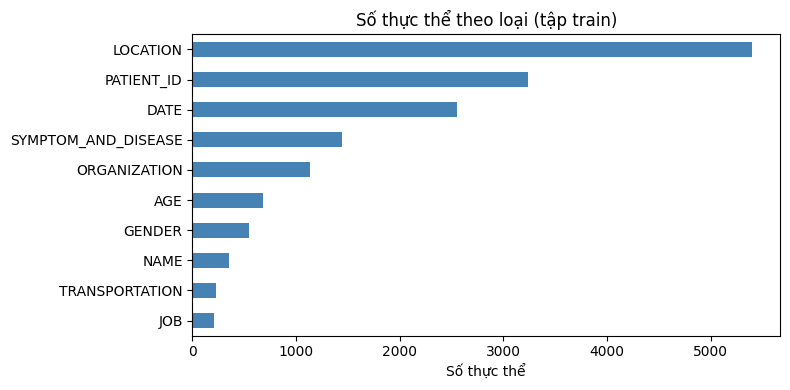

In [19]:
# Vẽ biểu đồ phân bố số thực thể trên tập train
thong_ke.drop("TỔNG")["train"].plot(kind="barh", figsize=(8, 4), color="steelblue")
plt.title("Số thực thể theo loại (tập train)")
plt.xlabel("Số thực thể")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

**Nhận xét:**
- Dữ liệu **mất cân bằng mạnh**: `LOCATION`, `PATIENT_ID`, `DATE` chiếm phần lớn; `JOB`, `TRANSPORTATION`, `NAME` rất ít.
- Vì vậy ngoài **micro-F1** (gộp mọi thực thể) mình báo cáo thêm **macro-F1** (trung bình F1 của 10 loại, mỗi loại có trọng số như nhau) và **F1 từng loại**.

## 2. Tiền xử lý: tách từ tiếng Việt

Tiếng Việt viết cách nhau theo **âm tiết** chứ không theo **từ**. Ví dụ "bệnh viện" gồm 2 âm tiết nhưng là 1 từ → sau khi tách từ thành `bệnh_viện`.

- Bộ dữ liệu PhoNER_COVID19 đã cung cấp sẵn bản **đã tách từ** (`data/word`). Theo bài báo, nhóm tác giả tách từ bằng **RDRSegmenter của VnCoreNLP**. Mình dùng bản này cho CRF để nhãn khớp đúng với từng từ.
- Với **văn bản mới** (người dùng tự nhập, chưa tách từ), mình dùng **`underthesea`** để tách từ trước khi đưa vào CRF (xem mục 3.5).

Dưới đây mình thử `underthesea` trên câu âm tiết gốc và so với bản tách từ của dataset.

In [20]:
from underthesea import word_tokenize

# Ghép các âm tiết thành câu văn bản thô
cau_tho = " ".join(dev_syl[0])
print("Câu thô (âm tiết):")
print(cau_tho)

# Tách từ bằng underthesea, format="text" sẽ nối từ ghép bằng dấu "_"
cau_tach_tu = word_tokenize(cau_tho, format="text")
print("\nunderthesea tách từ:")
print(cau_tach_tu)

print("\nDataset (VnCoreNLP) tách từ:")
print(" ".join(dev_sents[0]))

Câu thô (âm tiết):
Bác sĩ Nguyễn Trung Nguyên , Giám đốc Trung tâm Chống độc , Bệnh viện Bạch Mai , cho biết bệnh nhân được chuyển đến bệnh viện ngày 7/3 , chẩn đoán ngộ độc thuốc điều trị sốt rét chloroquine .

underthesea tách từ:
Bác_sĩ Nguyễn_Trung_Nguyên , Giám_đốc Trung_tâm Chống độc , Bệnh_viện Bạch_Mai , cho biết bệnh_nhân được chuyển đến bệnh_viện ngày 7/3 , chẩn_đoán ngộ_độc thuốc điều_trị sốt_rét chloroquine .

Dataset (VnCoreNLP) tách từ:
Bác_sĩ Nguyễn_Trung_Nguyên , Giám_đốc Trung_tâm Chống độc , Bệnh_viện Bạch_Mai , cho biết bệnh_nhân được chuyển đến bệnh_viện ngày 7/3 , chẩn_đoán ngộ_độc thuốc điều_trị sốt_rét chloroquine .


In [21]:
# So sánh underthesea với cách tách từ của dataset trên 300 câu dev
# Đếm xem có bao nhiêu câu mà 2 cách tách cho ra đúng cùng 1 dãy từ
so_cau_thu = 300
so_cau_giong = 0
for i in range(so_cau_thu):
    cau_tho = " ".join(dev_syl[i])
    tu_underthesea = word_tokenize(cau_tho, format="text").split()
    tu_dataset = dev_sents[i]
    if tu_underthesea == tu_dataset:
        so_cau_giong += 1

print(f"Số câu underthesea tách giống hệt dataset: {so_cau_giong}/{so_cau_thu} "
      f"({so_cau_giong / so_cau_thu:.1%})")

Số câu underthesea tách giống hệt dataset: 155/300 (51.7%)


In [22]:
# Xem cụ thể 2 cách tách từ khác nhau ở những chỗ nào (chỉ in đoạn khác, không in cả câu)
from collections import Counter
from difflib import SequenceMatcher

dem_khac = Counter()   # (dataset, underthesea) -> số lần xuất hiện
cau_khac = []          # (chỉ số câu, danh sách chỗ khác nhau)
for i in range(so_cau_thu):
    tu_underthesea = word_tokenize(" ".join(dev_syl[i]), format="text").split()
    tu_dataset = dev_sents[i]
    if tu_underthesea == tu_dataset:
        continue
    cho_khac = []
    for tag, a1, a2, b1, b2 in SequenceMatcher(None, tu_dataset, tu_underthesea, autojunk=False).get_opcodes():
        if tag == "equal":
            continue
        cap = (" ".join(tu_dataset[a1:a2]), " ".join(tu_underthesea[b1:b2]))
        cho_khac.append(cap)
        dem_khac[cap] += 1
    cau_khac.append((i, cho_khac))

print(f"{len(cau_khac)} câu khác nhau, tổng {sum(dem_khac.values())} chỗ khác nhau")

# 1) Ví dụ chi tiết: 10 câu khác nhau đầu tiên
print("=== 10 câu khác nhau đầu tiên ===")
for i, cho_khac in cau_khac[:10]:
    print(f"Câu {i}:")
    for ds, ut in cho_khac:
        print(f"   dataset: {ds!r:35} | underthesea: {ut!r}")

# 2) Các kiểu khác nhau hay gặp nhất
print("=== 20 kiểu khác nhau hay gặp nhất ===")
for (ds, ut), n in dem_khac.most_common(20):
    print(f"{n:3}x  dataset: {ds!r:35} | underthesea: {ut!r}")

145 câu khác nhau, tổng 234 chỗ khác nhau
=== 10 câu khác nhau đầu tiên ===
Câu 1:
   dataset: 'Bắc_Từ_Liêm'                       | underthesea: 'Bắc Từ_Liêm'
Câu 6:
   dataset: 'Biên_Hoà'                          | underthesea: 'Biên_Hòa'
Câu 7:
   dataset: 'Phú_Thọ Hoà'                       | underthesea: 'Phú_Thọ_Hòa'
Câu 9:
   dataset: 'Hệ_miễn_dịch'                      | underthesea: 'Hệ miễn_dịch'
Câu 13:
   dataset: 'toà'                               | underthesea: 'tòa'
Câu 14:
   dataset: '82,4%'                             | underthesea: '82,4 %'
   dataset: 'đái_tháo_đường'                    | underthesea: 'đái_tháo đường'
Câu 17:
   dataset: '21h'                               | underthesea: '21 h'
   dataset: 'Hoà_Vang'                          | underthesea: 'Hòa_Vang'
Câu 20:
   dataset: 'xơ phổi'                           | underthesea: 'xơ_phổi'
Câu 22:
   dataset: 'tuổi'                            | underthesea: 'tuổi'
   dataset: 'phường Hoà_Minh'          

**Nhận xét:** hai công cụ tách từ không giống nhau hoàn toàn (khác nhau ở từ ghép, tên riêng, số...). Nếu mình tự tách lại bằng `underthesea` thì phải **căn chỉnh lại nhãn**, dễ gây sai lệch ranh giới thực thể. Vì vậy khi **train và đánh giá** mình dùng bản đã tách sẵn của dataset; `underthesea` chỉ dùng cho **văn bản mới**.

## 3. (A) Baseline CRF

### 3.1 Ý tưởng
**CRF (Conditional Random Field)** là mô hình xác suất cho bài toán gán nhãn chuỗi. Khác với việc phân loại từng từ độc lập, CRF xét **cả chuỗi nhãn** cùng lúc, nên học được quy luật chuyển nhãn, ví dụ:
- `I-LOCATION` chỉ được đứng sau `B-LOCATION` hoặc `I-LOCATION`;
- sau từ "bệnh_nhân" thường là `B-PATIENT_ID`.

CRF không tự hiểu được chữ, nên mình phải **tự thiết kế đặc trưng (feature)** cho mỗi từ: chính từ đó, viết hoa hay không, có phải số không, các từ xung quanh...

In [23]:
def hinh_dang_tu(tu):
    """Biến từ thành 'hình dạng': chữ hoa -> X, chữ thường -> x, số -> d.
    Ví dụ: 'Hà_Nội' -> 'Xx_Xx', '19/3' -> 'd/d', 'VN0054' -> 'Xd'.
    Các ký tự giống nhau liên tiếp được gộp lại cho gọn."""
    ket_qua = ""
    for ky_tu in tu:
        if ky_tu.isupper():
            k = "X"
        elif ky_tu.islower():
            k = "x"
        elif ky_tu.isdigit():
            k = "d"
        else:
            k = ky_tu
        if ket_qua == "" or ket_qua[-1] != k:
            ket_qua += k
    return ket_qua


print(hinh_dang_tu("Hà_Nội"), hinh_dang_tu("19/3"), hinh_dang_tu("VN0054"), hinh_dang_tu("bệnh_nhân"))

Xx_Xx d/d Xd x_x


In [24]:
def word2features(cau, i):
    """Tạo đặc trưng cho từ thứ i trong câu.
    Trả về 1 dict: tên đặc trưng -> giá trị."""
    tu = cau[i]

    dac_trung = {
        "bias": 1.0,
        # --- đặc trưng của chính từ đó ---
        "tu.lower": tu.lower(),                 # từ viết thường
        "tu.istitle": tu.istitle(),             # viết hoa chữ đầu (tên riêng)
        "tu.isupper": tu.isupper(),             # viết hoa toàn bộ (viết tắt: HCDC, BV)
        "tu.isdigit": tu.isdigit(),             # là số (mã bệnh nhân, tuổi)
        "tu.co_gach_duoi": "_" in tu,           # là từ ghép (bệnh_viện)
        "tu.hinh_dang": hinh_dang_tu(tu),
        "tu.tien_to_3": tu[:3].lower(),         # 3 ký tự đầu
        "tu.hau_to_3": tu[-3:].lower(),         # 3 ký tự cuối
        "tu.am_tiet_dau": tu.split("_")[0].lower(),   # 'bệnh' trong 'bệnh_viện'
        "tu.am_tiet_cuoi": tu.split("_")[-1].lower(), # 'viện' trong 'bệnh_viện'
    }

    # --- đặc trưng của 1 từ phía trước ---
    if i > 0:
        tu_truoc = cau[i - 1]
        dac_trung["-1:tu.lower"] = tu_truoc.lower()
        dac_trung["-1:tu.istitle"] = tu_truoc.istitle()
        dac_trung["-1:tu.isdigit"] = tu_truoc.isdigit()
        dac_trung["-1:tu.hinh_dang"] = hinh_dang_tu(tu_truoc)
        dac_trung["-1:bigram"] = tu_truoc.lower() + "|" + tu.lower()
    else:
        dac_trung["BOS"] = True   # đầu câu (Begin Of Sentence)

    # --- đặc trưng của 2 từ phía trước ---
    if i > 1:
        dac_trung["-2:tu.lower"] = cau[i - 2].lower()

    # --- đặc trưng của 1 từ phía sau ---
    if i < len(cau) - 1:
        tu_sau = cau[i + 1]
        dac_trung["+1:tu.lower"] = tu_sau.lower()
        dac_trung["+1:tu.istitle"] = tu_sau.istitle()
        dac_trung["+1:tu.isdigit"] = tu_sau.isdigit()
        dac_trung["+1:tu.hinh_dang"] = hinh_dang_tu(tu_sau)
        dac_trung["+1:bigram"] = tu.lower() + "|" + tu_sau.lower()
    else:
        dac_trung["EOS"] = True   # cuối câu (End Of Sentence)

    # --- đặc trưng của 2 từ phía sau ---
    if i < len(cau) - 2:
        dac_trung["+2:tu.lower"] = cau[i + 2].lower()

    return dac_trung


def sent2features(cau):
    """Đặc trưng cho cả câu = list đặc trưng của từng từ."""
    return [word2features(cau, i) for i in range(len(cau))]


# Xem thử đặc trưng của từ "Y_tế" trong câu đầu tiên
print(train_sents[0])
word2features(train_sents[0], 16)

['Đồng_thời', ',', 'bệnh_viện', 'tiếp_tục', 'thực_hiện', 'các', 'biện_pháp', 'phòng_chống', 'dịch_bệnh', 'COVID', '-', '19', 'theo', 'hướng_dẫn', 'của', 'Bộ', 'Y_tế', '.']


{'bias': 1.0,
 'tu.lower': 'y_tế',
 'tu.istitle': False,
 'tu.isupper': False,
 'tu.isdigit': False,
 'tu.co_gach_duoi': True,
 'tu.hinh_dang': 'X_x',
 'tu.tien_to_3': 'y_t',
 'tu.hau_to_3': '_tế',
 'tu.am_tiet_dau': 'y',
 'tu.am_tiet_cuoi': 'tế',
 '-1:tu.lower': 'bộ',
 '-1:tu.istitle': True,
 '-1:tu.isdigit': False,
 '-1:tu.hinh_dang': 'Xx',
 '-1:bigram': 'bộ|y_tế',
 '-2:tu.lower': 'của',
 '+1:tu.lower': '.',
 '+1:tu.istitle': False,
 '+1:tu.isdigit': False,
 '+1:tu.hinh_dang': '.',
 '+1:bigram': 'y_tế|.'}

In [25]:
# Chuyển toàn bộ dữ liệu sang dạng đặc trưng
X_train = [sent2features(c) for c in train_sents]
X_dev   = [sent2features(c) for c in dev_sents]
X_test  = [sent2features(c) for c in test_sents]

y_train = train_tags
y_dev   = dev_tags
y_test  = test_tags

print("Đã tạo đặc trưng cho", len(X_train), "câu train,", len(X_dev), "câu dev,", len(X_test), "câu test")

Đã tạo đặc trưng cho 5027 câu train, 2000 câu dev, 3000 câu test


### 3.2 Chọn siêu tham số trên tập dev

CRF trong `sklearn-crfsuite` có 2 hệ số **regularization** (chống overfit):
- `c1`: hệ số L1 → đẩy trọng số của các đặc trưng không quan trọng về 0.
- `c2`: hệ số L2 → giữ cho trọng số không quá lớn.

Mình thử vài cặp `(c1, c2)`, train trên **train**, đo F1 trên **dev**, chọn cặp tốt nhất. Tập **test chỉ dùng 1 lần ở cuối** để báo cáo, tránh "nhìn trộm" test.

In [26]:
cac_cau_hinh = [
    (0.1, 0.1),
    (0.05, 0.05),
    (0.3, 0.05),
    (0.01, 0.01),
]

ket_qua_dev = []
for c1, c2 in cac_cau_hinh:
    bat_dau = time.time()
    crf_thu = sklearn_crfsuite.CRF(
        algorithm="lbfgs",             # thuật toán tối ưu L-BFGS
        c1=c1,
        c2=c2,
        max_iterations=100,            # tối đa 100 vòng lặp tối ưu
        all_possible_transitions=True,   # học cả những chuyển nhãn không xuất hiện trong train
    )
    crf_thu.fit(X_train, y_train)
    y_dev_pred = crf_thu.predict(X_dev)
    f1_dev = f1_score(y_dev, y_dev_pred)
    ket_qua_dev.append({"c1": c1, "c2": c2, "F1_dev": round(f1_dev, 4),
                        "thoi_gian (s)": round(time.time() - bat_dau, 1)})
    print(f"c1={c1}, c2={c2} -> micro-F1 dev = {f1_dev:.4f}")

bang_dev = pd.DataFrame(ket_qua_dev)
bang_dev

c1=0.1, c2=0.1 -> micro-F1 dev = 0.9238
c1=0.05, c2=0.05 -> micro-F1 dev = 0.9246
c1=0.3, c2=0.05 -> micro-F1 dev = 0.9227
c1=0.01, c2=0.01 -> micro-F1 dev = 0.9231


,c1,c2,F1_dev,thoi_gian (s)
0,0.10,0.10,0.9238,20.3
1,0.05,0.05,0.9246,19.2
2,0.30,0.05,0.9227,21.7
3,0.01,0.01,0.9231,20.7


In [27]:
# Lấy cấu hình có F1 dev cao nhất
dong_tot_nhat = bang_dev.sort_values("F1_dev", ascending=False).iloc[0]
C1_TOT = float(dong_tot_nhat["c1"])
C2_TOT = float(dong_tot_nhat["c2"])
print("Cấu hình tốt nhất trên dev: c1 =", C1_TOT, ", c2 =", C2_TOT)

Cấu hình tốt nhất trên dev: c1 = 0.05 , c2 = 0.05


### 3.3 Train model cuối cùng và đánh giá trên test

Train lại CRF với cấu hình tốt nhất (trên tập train), sau đó đánh giá **1 lần** trên test.

`seqeval` đánh giá theo **thực thể**: một thực thể dự đoán chỉ được tính là đúng khi **đúng cả loại và đúng cả ranh giới** (từ đầu đến từ cuối).

In [28]:
crf = sklearn_crfsuite.CRF(
    algorithm="lbfgs",             # thuật toán tối ưu L-BFGS
    c1=C1_TOT,
    c2=C2_TOT,
    max_iterations=100,            # tối đa 100 vòng lặp tối ưu
    all_possible_transitions=True,
)
bat_dau = time.time()
crf.fit(X_train, y_train)
print(f"Train xong trong {time.time() - bat_dau:.1f} giây")

y_test_pred_crf = crf.predict(X_test)

print("=== CRF (dữ liệu đã tách từ) trên TEST ===")
print(classification_report(y_test, y_test_pred_crf, digits=4))

Train xong trong 20.4 giây
=== CRF (dữ liệu đã tách từ) trên TEST ===
                     precision    recall  f1-score   support

                AGE     0.9444    0.9347    0.9396       582
               DATE     0.9755    0.9861    0.9808      1654
             GENDER     0.9593    0.9177    0.9381       462
                JOB     0.7009    0.4335    0.5357       173
           LOCATION     0.9265    0.9171    0.9218      4441
               NAME     0.9460    0.8270    0.8826       318
       ORGANIZATION     0.8887    0.8080    0.8465       771
         PATIENT_ID     0.9659    0.9751    0.9705      2005
SYMPTOM_AND_DISEASE     0.8958    0.7342    0.8070      1136
     TRANSPORTATION     0.9728    0.9275    0.9496       193

          micro avg     0.9372    0.9034    0.9200     11735
          macro avg     0.9176    0.8461    0.8772     11735
       weighted avg     0.9348    0.9034    0.9176     11735



In [29]:
def tom_tat_ket_qua(ten, y_that, y_du_doan):
    """Gom các chỉ số chính vào 1 dict để làm bảng so sánh."""
    return {
        "Mô hình": ten,
        "Precision (micro)": round(float(precision_score(y_that, y_du_doan)), 4),
        "Recall (micro)": round(float(recall_score(y_that, y_du_doan)), 4),
        "F1 (micro)": round(float(f1_score(y_that, y_du_doan)), 4),
        "F1 (macro)": round(float(f1_score(y_that, y_du_doan, average="macro", zero_division=0)), 4),
    }


CAC_LOAI_THUC_THE = ["PATIENT_ID", "NAME", "AGE", "GENDER", "JOB", "LOCATION",
                     "ORGANIZATION", "SYMPTOM_AND_DISEASE", "TRANSPORTATION", "DATE"]


def f1_tung_loai(y_that, y_du_doan):
    """Trả về dict: loại thực thể -> F1."""
    bao_cao = classification_report(y_that, y_du_doan, output_dict=True, zero_division=0)
    ket_qua = {}
    for loai, chi_so in bao_cao.items():
        if loai in CAC_LOAI_THUC_THE:   # chỉ lấy 10 loại thực thể, bỏ các dòng micro/macro/weighted avg
            ket_qua[loai] = round(chi_so["f1-score"], 4)
    return ket_qua


kq_crf = tom_tat_ket_qua("CRF (tách từ)", y_test, y_test_pred_crf)
kq_crf

{'Mô hình': 'CRF (tách từ)',
 'Precision (micro)': 0.9372,
 'Recall (micro)': 0.9034,
 'F1 (micro)': 0.92,
 'F1 (macro)': 0.8772}

### 3.4 Đặc trưng mạnh nhất cho PATIENT_ID và ORGANIZATION

Xem những đặc trưng mà CRF dựa vào nhiều nhất để nhận diện hai loại thực thể đặc thù mà đề bài yêu cầu phân tích. Kết quả này được dùng lại để giải thích lỗi ở mục 4.

In [30]:
# Đặc trưng mạnh nhất cho 2 loại thực thể đặc thù mà đề bài yêu cầu phân tích
# Counter(dict) biến dict thành bộ đếm; .most_common() sắp xếp từ trọng số lớn đến nhỏ
dac_trung_manh = Counter(crf.state_features_)

for nhan_can_xem in ["B-PATIENT_ID", "B-ORGANIZATION"]:
    print(f"Top 10 đặc trưng cho {nhan_can_xem}:")
    dem = 0
    for (ten_dac_trung, nhan), trong_so in dac_trung_manh.most_common():
        if nhan == nhan_can_xem:
            print(f"   {trong_so:7.3f}  {ten_dac_trung}")
            dem += 1
            if dem == 10:
                break
    print()

Top 10 đặc trưng cho B-PATIENT_ID:
     5.623  -1:tu.lower:bệnh_nhân
     3.621  -1:tu.lower:bệnh
     3.458  -1:tu.lower:số
     3.418  -1:tu.lower:và
     3.229  +1:bigram:11|tử_vong
     3.144  tu.hinh_dang:Xd
     3.097  tu.isdigit
     3.097  tu.hinh_dang:d
     2.882  -1:bigram:thứ|17
     2.645  -1:tu.lower:thứ

Top 10 đặc trưng cho B-ORGANIZATION:
     3.755  tu.hau_to_3:cdc
     3.718  BOS
     3.398  -2:tu.lower:khảo_sát
     2.758  -2:tu.lower:xét_nghiệm
     2.437  -1:tu.lower:trưởng
     2.359  tu.am_tiet_cuoi:airlines
     2.220  tu.hau_to_3:nes
     2.140  -2:tu.lower:9
     2.122  -1:bigram:giám_đốc|bệnh_viện
     2.109  tu.am_tiet_dau:bộ



### 3.5 Dùng CRF cho câu mới (có bước tách từ bằng `underthesea`)

Với văn bản người dùng tự nhập: **tách từ bằng underthesea → tạo đặc trưng → CRF dự đoán**.

In [31]:
def crf_du_doan_cau_moi(van_ban):
    # Bước 1: tách từ tiếng Việt
    cac_tu = word_tokenize(van_ban, format="text").split()
    # Bước 2: tạo đặc trưng và dự đoán
    cac_nhan = crf.predict_single(sent2features(cac_tu))
    # Bước 3: in ra các thực thể tìm được
    for loai, dau, cuoi in get_entities(cac_nhan):
        print(f"  [{loai}] {' '.join(cac_tu[dau:cuoi + 1])}")


cau_vi_du = ("Bệnh nhân 91 là phi công người Anh, 43 tuổi, đang điều trị tại "
             "Bệnh viện Bệnh Nhiệt đới TP.HCM, từng bay chuyến VN0054 ngày 18/3.")
print(cau_vi_du)
crf_du_doan_cau_moi(cau_vi_du)

Bệnh nhân 91 là phi công người Anh, 43 tuổi, đang điều trị tại Bệnh viện Bệnh Nhiệt đới TP.HCM, từng bay chuyến VN0054 ngày 18/3.
  [PATIENT_ID] 91
  [JOB] phi_công
  [AGE] 43
  [LOCATION] Bệnh_viện Bệnh Nhiệt_đới TP.HCM
  [TRANSPORTATION] VN0054
  [DATE] 18/3


In [32]:
# Lưu model CRF để các bạn trong nhóm dùng lại (ví dụ cho demo)
import joblib
os.makedirs(KET_QUA_DIR, exist_ok=True)
duong_dan_model = os.path.join(KET_QUA_DIR, "crf_model.pkl")
joblib.dump(crf, duong_dan_model)
print("Đã lưu model vào", duong_dan_model)

Đã lưu model vào ..\results\phan_tich\crf_model.pkl


## 4. Phân tích lỗi CRF

Với mỗi thực thể **đúng (gold)**, mình so với các thực thể **dự đoán** trong cùng câu và chia lỗi thành các nhóm:

| Nhóm lỗi | Ý nghĩa |
|---|---|
| **Bỏ sót** | Không dự đoán thực thể nào chồng lên vị trí gold |
| **Sai biên** | Đúng loại nhưng ranh giới (từ đầu/cuối) bị lệch |
| **Sai loại** | Đúng ranh giới nhưng gán sai loại (vd: ORGANIZATION ↔ LOCATION) |
| **Sai cả biên và loại** | Lệch ranh giới và sai loại |
| **Dự đoán thừa** | Model đoán ra thực thể ở chỗ không có thực thể gold nào |

In [33]:
def chong_len_nhau(thuc_the_a, thuc_the_b):
    """Hai thực thể (loại, vị_trí_đầu, vị_trí_cuối) có CHỒNG LÊN nhau không?
    Chồng lên = có ít nhất 1 từ dùng chung.
    Ví dụ: (A, 2, 4) và (B, 4, 6) chồng nhau ở từ số 4  -> True
           (A, 2, 4) và (B, 5, 6) không có từ chung     -> False"""
    dau_a, cuoi_a = thuc_the_a[1], thuc_the_a[2]
    dau_b, cuoi_b = thuc_the_b[1], thuc_the_b[2]
    return dau_a <= cuoi_b and cuoi_a >= dau_b


def phan_loai_loi(cac_cau, y_that, y_du_doan):
    """Trả về DataFrame, mỗi dòng là 1 lỗi: nhóm lỗi, loại gold, loại dự đoán, ví dụ.
    Đầu vào : cac_cau (list câu, mỗi câu là list từ), y_that và y_du_doan (list nhãn BIO của từng câu).
    Đầu ra  : bảng các lỗi với cột nhom_loi / loai_gold / text_gold / loai_du_doan / text_du_doan / cau."""
    danh_sach_loi = []

    for cau, nhan_that, nhan_doan in zip(cac_cau, y_that, y_du_doan):
        gold = get_entities(nhan_that)    # list (loại, đầu, cuối)
        pred = get_entities(nhan_doan)
        van_ban_cau = " ".join(cau)

        # --- Xét từng thực thể gold ---
        for loai_g, dau_g, cuoi_g in gold:
            if (loai_g, dau_g, cuoi_g) in pred:
                continue   # đoán đúng hoàn toàn -> không phải lỗi

            # tìm các thực thể dự đoán chồng lên vị trí của gold
            chong_len = [p for p in pred if chong_len_nhau(p, (loai_g, dau_g, cuoi_g))]

            if len(chong_len) == 0:
                nhom = "Bỏ sót"
                loai_p, text_p = "-", "-"
            else:
                loai_p, dau_p, cuoi_p = chong_len[0]
                text_p = " ".join(cau[dau_p:cuoi_p + 1])
                cung_bien = (dau_p == dau_g and cuoi_p == cuoi_g)
                cung_loai = (loai_p == loai_g)
                if cung_loai:
                    nhom = "Sai biên"
                elif cung_bien:
                    nhom = "Sai loại"
                else:
                    nhom = "Sai cả biên và loại"

            danh_sach_loi.append({
                "nhom_loi": nhom,
                "loai_gold": loai_g,
                "text_gold": " ".join(cau[dau_g:cuoi_g + 1]),
                "loai_du_doan": loai_p,
                "text_du_doan": text_p,
                "cau": van_ban_cau,
            })

        # --- Xét các thực thể dự đoán thừa ---
        for loai_p, dau_p, cuoi_p in pred:
            chong_len = [g for g in gold if chong_len_nhau(g, (loai_p, dau_p, cuoi_p))]
            if len(chong_len) == 0:
                danh_sach_loi.append({
                    "nhom_loi": "Dự đoán thừa",
                    "loai_gold": "-",
                    "text_gold": "-",
                    "loai_du_doan": loai_p,
                    "text_du_doan": " ".join(cau[dau_p:cuoi_p + 1]),
                    "cau": van_ban_cau,
                })

    return pd.DataFrame(danh_sach_loi)


loi_crf = phan_loai_loi(test_sents, y_test, y_test_pred_crf)
print("Tổng số lỗi:", len(loi_crf))
loi_crf["nhom_loi"].value_counts()

Tổng số lỗi: 1352


nhom_loi
Bỏ sót                 639
Sai biên               291
Dự đoán thừa           218
Sai loại               125
Sai cả biên và loại     79
Name: count, dtype: int64

In [34]:
# Bảng chéo: mỗi loại thực thể gold bị mắc nhóm lỗi nào bao nhiêu lần
bang_loi = pd.crosstab(loi_crf["loai_gold"], loi_crf["nhom_loi"])
bang_loi = bang_loi.drop("-", errors="ignore")
bang_loi

nhom_loi,Bỏ sót,Dự đoán thừa,Sai biên,Sai cả biên và loại,Sai loại
loai_gold,,,,,
AGE,29,0,0,6,3
DATE,9,0,5,2,7
GENDER,37,0,0,0,1
JOB,92,0,4,1,1
LOCATION,121,0,185,22,40
NAME,46,0,2,1,6
ORGANIZATION,44,0,22,29,53
PATIENT_ID,15,0,19,6,10
SYMPTOM_AND_DISEASE,240,0,54,7,1


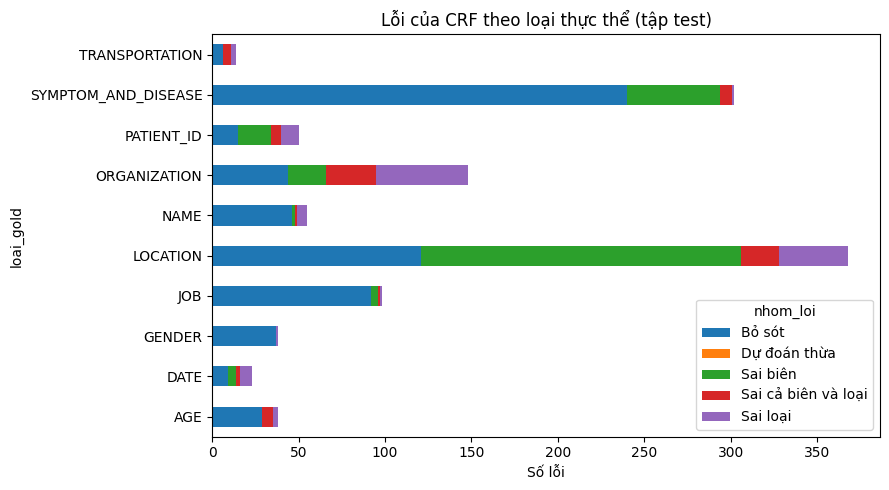

In [35]:
# Biểu đồ số lỗi theo loại thực thể
bang_loi.plot(kind="barh", stacked=True, figsize=(9, 5))
plt.title("Lỗi của CRF theo loại thực thể (tập test)")
plt.xlabel("Số lỗi")
plt.tight_layout()
plt.show()

### 4.1 Lỗi trên thực thể đặc thù: số ca bệnh (`PATIENT_ID`)

In [36]:
loi_patient = loi_crf[(loi_crf["loai_gold"] == "PATIENT_ID") | (loi_crf["loai_du_doan"] == "PATIENT_ID")]
print("Số lỗi liên quan PATIENT_ID:", len(loi_patient))
print(loi_patient["nhom_loi"].value_counts(), "\n")

# Những loại nào hay bị nhầm với PATIENT_ID?
print("Nhầm lẫn PATIENT_ID (gold -> dự đoán):")
print(loi_patient.groupby(["loai_gold", "loai_du_doan"]).size().sort_values(ascending=False).head(8))

Số lỗi liên quan PATIENT_ID: 94
nhom_loi
Dự đoán thừa           22
Sai loại               21
Sai biên               19
Sai cả biên và loại    17
Bỏ sót                 15
Name: count, dtype: int64 

Nhầm lẫn PATIENT_ID (gold -> dự đoán):
loai_gold       loai_du_doan  
-               PATIENT_ID        22
PATIENT_ID      PATIENT_ID        19
                -                 15
LOCATION        PATIENT_ID        12
PATIENT_ID      DATE              11
                TRANSPORTATION     4
DATE            PATIENT_ID         4
TRANSPORTATION  PATIENT_ID         3
dtype: int64


In [37]:
pd.set_option("display.max_colwidth", 200)
loi_patient[["nhom_loi", "loai_gold", "text_gold", "loai_du_doan", "text_du_doan", "cau"]].head(8)

,nhom_loi,loai_gold,text_gold,loai_du_doan,text_du_doan,cau
33,Bỏ sót,PATIENT_ID,32,-,-,"Các bệnh_nhân 17 , 21 , 32 sức_khoẻ đang tiến_triển tốt Mạng xã_hội có nhiều tin_đồn về sức_khoẻ các bệnh_nhân COVID - 19 đang được điều_trị , đặc_biệt là bệnh_nhân 17 N.H.N. , bệnh_nhân 21 N.Q.T...."
59,Sai loại,PATIENT_ID,N133,NAME,N133,"Bệnh_nhân được chuyển tới Bệnh_viện Bạch_Mai nằm tại phòng điều_trị tự nguyên , khoa thần_kinh , nằm cùng phòng với bệnh_nhân N133 từ ngày 17 - 3 ."
61,Sai biên,PATIENT_ID,BN 1068,PATIENT_ID,1068,"Ca bệnh 1068 ( BN 1068 ) : bệnh_nhân nam , 36 tuổi , ngụ xã Thạnh_Phú , huyện Cái_Nước , Cà_Mau ."
64,Bỏ sót,PATIENT_ID,1.024,-,-,"Hai bệnh_nhân 1.023 - 1.024 được lấy mẫu ngày 24 - 8 tại khu_vực đang được phong_toả thuộc phường Hoà_Tiến , quận Hoà_Vang , thành_phố Đà_Nẵng ."
83,Sai loại,LOCATION,591,PATIENT_ID,591,"Ngoài "" bệnh_nhân 592 "" , tại huyện Duy_Xuyên còn ghi_nhận ca nhiễm mới là "" bệnh_nhân 591 "" , nữ , 63 tuổi , xã Duy_Phước ."
84,Dự đoán thừa,-,-,PATIENT_ID,87,"45 bệnh_nhân tuổi từ 27 đến 87 , bao_gồm 33 trường_hợp tại Bệnh_viện Đà_Nẵng , bốn tại Bệnh_viện Phổi Đà_Nẵng , hai tại Bệnh_viện ung_bướu Đà_Nẵng , bốn tại khách_sạn đang cách_ly bệnh_nhân thận n..."
100,Sai cả biên và loại,LOCATION,quận 8,PATIENT_ID,8,"Trường_hợp bệnh_nhân 64 ( ngụ phường 2 , quận 8 ) : tổng_số người tiếp_xúc 88 , trong đó 20 người tiếp_xúc trên chuyến bay EK392 đang xác_minh ."
104,Sai loại,DATE,23,PATIENT_ID,23,"Trong tháng 7 , bệnh_nhân đi làm tại Trung_tâm hành_chính Đà_Nẵng các ngày 22 , 23 , 24 , 27 , tiếp_xúc với nhiều đồng_nghiệp trong cơ_quan ."


### 4.2 Lỗi trên thực thể đặc thù: tên tổ chức y tế (`ORGANIZATION`)

In [38]:
loi_org = loi_crf[loi_crf["loai_gold"] == "ORGANIZATION"]
print("Số thực thể ORGANIZATION bị sai:", len(loi_org))
print(loi_org["nhom_loi"].value_counts(), "\n")
print("ORGANIZATION hay bị nhầm thành:")
print(loi_org["loai_du_doan"].value_counts())

Số thực thể ORGANIZATION bị sai: 148
nhom_loi
Sai loại               53
Bỏ sót                 44
Sai cả biên và loại    29
Sai biên               22
Name: count, dtype: int64 

ORGANIZATION hay bị nhầm thành:
loai_du_doan
LOCATION        81
-               44
ORGANIZATION    22
PATIENT_ID       1
Name: count, dtype: int64


In [39]:
# Ví dụ ORGANIZATION bị gán thành LOCATION
loi_org[loi_org["loai_du_doan"] == "LOCATION"][["text_gold", "text_du_doan", "cau"]].head(6)

,text_gold,text_du_doan,cau
1,Bệnh_viện Chợ_Rẫy,Bệnh_viện Chợ_Rẫy,"Bác_sĩ Trần_Thanh_Linh , từ Bệnh_viện Chợ_Rẫy chi_viện phụ_trách đơn_nguyên hồi_sức tích_cực , cho biết "" bệnh_nhân 416 "" vẫn đang duy_trì ECMO , thở máy , hiện xơ phổi rất nhiều ."
27,"Hội Thanh_niên , sinh_viên Việt_Nam tại Czech",Việt_Nam,"Thân_nhân bệnh_nhân 94 đang có kết_quả âm_tính Chị Nguyễn_Thị_Diệu_Linh cho biết chiều 21 - 3 , ngay khi Việt_Nam công_bố ca bệnh 94 dương_tính với COVID - 19 là nữ , 64 tuổi , quốc_tịch Việt_Nam ..."
36,khoa bệnh nhiệt_đới Bệnh_viện Chợ_Rẫy,khoa bệnh nhiệt_đới Bệnh_viện Chợ_Rẫy,"Bác_sĩ Nguyễn_Ngọc_Sang ( khoa bệnh nhiệt_đới Bệnh_viện Chợ_Rẫy ) , một trong các bác_sĩ được chọn chăm_sóc , điều_trị cho hai bệnh_nhân Trung_Quốc nhiễm virus corona trong phòng cách_ly đặc_biệt ..."
45,Khoa_Chấn thương chỉnh_hình bệnh_viện Xanh_Pôn,bệnh_viện Xanh_Pôn,"Khoa_Chấn thương chỉnh_hình bệnh_viện Xanh_Pôn tối 30/3 hoạt_động sau gần hai ngày cách_ly và 11 người liên_quan "" bệnh_nhân 175 "" xét_nghiệm âm_tính ."
50,Trạm thu phí Tam_Kỳ,Tam_Kỳ,"Chiều 22/7 , cô_giáo chở con gái đi học cờ_vua tại Trường tiểu_học Ngô_Gia_Tự ( quận Sơn_Trà ) và tiếp_xúc với bạn là nam "" bệnh_nhân 736 "" , 39 tuổi , giám_đốc Trạm thu phí Tam_Kỳ ."
51,Công_an huyện Bá_Thước,huyện Bá_Thước,"Phòng Cảnh_sát giao_thông Công_an tỉnh Thanh_Hoá đã phối_hợp Công_an huyện Bá_Thước rà_soát , đưa 15 người có_mặt trên xe_khách đến Bệnh_viện Đa_khoa Bá_Thước để cách_ly , theo_dõi ."


In [40]:
# Các nhóm lỗi khác: ví dụ bỏ sót SYMPTOM_AND_DISEASE và JOB (2 loại có F1 thấp)
loi_crf[(loi_crf["nhom_loi"] == "Bỏ sót") &
        (loi_crf["loai_gold"].isin(["SYMPTOM_AND_DISEASE", "JOB"]))][["loai_gold", "text_gold", "cau"]].head(8)

,loai_gold,text_gold,cau
0,JOB,bán tạp_hoá,"Từ 24 - 7 đến 31 - 7 , bệnh_nhân được mẹ là bà H.T.P ( 47 tuổi ) đón về nhà ở phường Phước_Hoà ( bằng xe_máy ) , không đi đâu chỉ ra Tạp_hoá Phượng , chợ Vườn_Lài , phường An_Sơn cùng mẹ bán tạp_h..."
2,SYMPTOM_AND_DISEASE,xơ phổi rất nhiều,"Bác_sĩ Trần_Thanh_Linh , từ Bệnh_viện Chợ_Rẫy chi_viện phụ_trách đơn_nguyên hồi_sức tích_cực , cho biết "" bệnh_nhân 416 "" vẫn đang duy_trì ECMO , thở máy , hiện xơ phổi rất nhiều ."
10,SYMPTOM_AND_DISEASE,viêm phổi,"Khi vào khoa , các bác_sĩ nhận_định tình_trạng viêm phổi trên bệnh_nhân 64 tuổi tuổi , sức_khoẻ suy_kiệt ."
15,SYMPTOM_AND_DISEASE,tràn khí màng phổi đã dẫn_lưu,"Trước đó , khi điều_trị tại hai bệnh_viện ở Đà_Nẵng , bệnh_nhân viêm phổi nặng trên 10 năm , tràn khí màng phổi đã dẫn_lưu ."
16,SYMPTOM_AND_DISEASE,ói,"Sáng 24 - 2 , Trung_tâm kiểm_soát bệnh_tật tỉnh Thừa_Thiên_Huế đã tổ_chức họp_báo để công_bố thông_tin về nguyên_nhân tử_vong của nữ_sinh lớp 12 ở xã Vinh_Hiền , huyện Phú_Lộc sau khi bệnh_nhân nà..."
19,SYMPTOM_AND_DISEASE,ung_thư gan,"Các ca tiên_lượng nặng gồm bà_cụ 88 tuổi bị tai_biến mạch_máu não , bệnh_nhân người Thuỵ_Điển 64 tuổi ung_thư máu , và bệnh_nhân 71 tuổi người Vĩnh_Phúc ung_thư gan ."
26,JOB,tiểu_thương bán hải_sản,""" Bệnh_nhân 1013 "" , 51 tuổi , tiểu_thương bán hải_sản ở chợ Siêu_Thị , từng được lấy mẫu xét_nghiệm nCoV lần một ngày 16/8 và có kết_quả âm_tính ."
28,SYMPTOM_AND_DISEASE,COPD,Ông có tiền_sử bị phổi tắc_nghẽn mạn_tính ( COPD ) và u ác niệu_quản đã phẫu_thuật cách đây hai năm .


**Nhận xét phân tích lỗi CRF** (đọc kết hợp với bảng và ví dụ ở trên):
1. **Nhầm ORGANIZATION ↔ LOCATION**: trong 148 thực thể ORGANIZATION bị sai, 81 bị đoán thành LOCATION. Cùng một tên (vd "Bệnh viện Bạch Mai") theo hướng dẫn gán nhãn là `LOCATION` khi chỉ nơi chốn, là `ORGANIZATION` khi là chủ thể hành động. CRF chỉ nhìn các từ kề nhau (±2 từ) nên không đủ ngữ cảnh để phân biệt vai trò.
2. **Số nhập nhằng quanh PATIENT_ID** (94 lỗi liên quan: 22 dự đoán thừa, 15 bỏ sót, còn lại sai biên/sai loại). Bảng nhầm lẫn ở mục 4.1 cho thấy hai kiểu chính: (a) số nằm trong địa chỉ hoặc địa danh bị đoán thành mã bệnh nhân (LOCATION → PATIENT_ID, 12 ca, vd "quận 8" → `8`, "55 phố Yên_Ninh" → `55`, "sư_đoàn 317" → `317`); (b) mã bệnh nhân bị đoán thành DATE (11 ca). Nguyên nhân hợp lý: đặc trưng "là số" có trọng số dương lớn cho `B-PATIENT_ID` (mục 3.4), nên số xuất hiện ở chỗ khác dễ bị kéo về PATIENT_ID. Ngoài ra có lỗi sai biên do tiền tố `BN` (gold "BN 1068" nhưng đoán "1068"); trong train chỉ 8/3240 mã bệnh nhân có tiền tố `BN` nên CRF ít gặp dạng này.
3. **Bỏ sót / sai biên ở cụm dài, đa dạng** (SYMPTOM_AND_DISEASE, JOB, địa chỉ nhiều cấp): những cụm này ít lặp lại, nhiều từ chưa gặp trong train, nên đặc trưng dạng "từ cụ thể" của CRF không bao phủ được.

→ Đây là các điểm mà mô hình ngữ cảnh (PhoBERT fine-tune) được kỳ vọng làm tốt hơn.

## 5. (B) Zero-shot NER

### 5.1 Ý tưởng
Dùng một **model NER tiếng Việt đã được train sẵn** trên Hugging Face, gọi qua `pipeline("token-classification")`, **không fine-tune** trên PhoNER_COVID19.

Model chọn: **`NlpHUST/ner-vietnamese-electra-base`** — model ELECTRA tiếng Việt được fine-tune cho NER **tổng quát** (kiểu dữ liệu VLSP 2018), chỉ có các nhãn chung như người, địa điểm, tổ chức, khác. Bộ nhãn thực tế được in ra ở cell bên dưới (`id2label`); nếu tên nhãn khác bảng dưới thì chỉ cần sửa hàm `doi_nhan`.

Có thể đổi `MODEL_NAME` sang model NER tiếng Việt khác trên Hugging Face, phần code còn lại giữ nguyên.

**Vấn đề:** PhoNER_COVID19 có 10 loại thực thể đặc thù, model tổng quát chỉ có 3 loại tương ứng. Mình ánh xạ nhãn:

| Nhãn model tổng quát | Nhãn PhoNER_COVID19 |
|---|---|
| PERSON / PER | NAME |
| LOCATION / LOC | LOCATION |
| ORGANIZATION / ORG | ORGANIZATION |
| MISCELLANEOUS / MISC | (bỏ, không có nhãn tương ứng) |

7 loại còn lại (`PATIENT_ID, AGE, GENDER, JOB, SYMPTOM_AND_DISEASE, TRANSPORTATION, DATE`) **model không thể dự đoán** → F1 = 0. Đây đúng là điểm đề bài muốn phân tích.

**Vì sao dùng dữ liệu âm tiết?** Model này được train trên văn bản thô (chưa tách từ), nên mình ghép các âm tiết thành câu bình thường rồi đưa vào model, sau đó gán nhãn ngược lại cho từng âm tiết để so với nhãn gold mức âm tiết.

> ⚠️ Phần này cần Internet để tải model từ Hugging Face. Trên Colab nên bật GPU (*Runtime → Change runtime type → T4 GPU*), chạy 3000 câu test khoảng 1–2 phút; chạy bằng CPU sẽ lâu hơn (vài phút đến chục phút).

In [41]:
import torch
from transformers import pipeline

MODEL_NAME = "NlpHUST/ner-vietnamese-electra-base"

# device=0 là GPU, device=-1 là CPU
thiet_bi = 0 if torch.cuda.is_available() else -1
ner_zero_shot = pipeline(
    "token-classification",
    model=MODEL_NAME,
    aggregation_strategy="simple",   # gộp các subword/token liền nhau thành 1 thực thể
    device=thiet_bi,
)

# In ra bộ nhãn thật của model để kiểm tra bảng ánh xạ ở trên
print("Nhãn của model:", ner_zero_shot.model.config.id2label)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Nhãn của model: {0: 'B-LOCATION', 1: 'B-MISCELLANEOUS', 2: 'B-ORGANIZATION', 3: 'B-PERSON', 4: 'I-LOCATION', 5: 'I-MISCELLANEOUS', 6: 'I-ORGANIZATION', 7: 'I-PERSON', 8: 'O'}


In [42]:
# Thử model trên 1 câu
ket_qua_thu = ner_zero_shot("Bệnh nhân 91 là phi công người Anh, đang điều trị tại Bệnh viện Chợ Rẫy, TP.HCM.")
for thuc_the in ket_qua_thu:
    print(thuc_the)

{'entity_group': 'MISCELLANEOUS', 'score': np.float32(0.99813086), 'word': 'người Anh', 'start': 25, 'end': 34}
{'entity_group': 'ORGANIZATION', 'score': np.float32(0.99912685), 'word': 'Bệnh viện Chợ Rẫy', 'start': 54, 'end': 71}
{'entity_group': 'LOCATION', 'score': np.float32(0.9988529), 'word': 'TP. HCM', 'start': 73, 'end': 79}


In [43]:
def doi_nhan(nhan_model):
    """Ánh xạ nhãn của model tổng quát sang nhãn PhoNER_COVID19.
    Trả về None nếu không có nhãn tương ứng."""
    nhan = nhan_model.upper()
    if "PER" in nhan:
        return "NAME"
    if "LOC" in nhan:
        return "LOCATION"
    if "ORG" in nhan:
        return "ORGANIZATION"
    return None   # MISC hoặc nhãn khác -> bỏ


def chuyen_sang_nhan_BIO(cac_am_tiet, cac_thuc_the):
    """Chuyển kết quả của pipeline (thực thể theo vị trí KÝ TỰ)
    thành nhãn BIO cho từng ÂM TIẾT.
    Đầu vào : cac_am_tiet - list âm tiết của câu; cac_thuc_the - list dict của pipeline,
              mỗi dict có 'entity_group', 'start', 'end' (vị trí KÝ TỰ trong câu " ".join(cac_am_tiet)).
    Đầu ra  : list nhãn BIO, cùng độ dài với cac_am_tiet."""
    # Tính vị trí ký tự bắt đầu - kết thúc của từng âm tiết trong câu " ".join(cac_am_tiet)
    vi_tri = []
    bat_dau = 0
    for am_tiet in cac_am_tiet:
        ket_thuc = bat_dau + len(am_tiet)
        vi_tri.append((bat_dau, ket_thuc))
        bat_dau = ket_thuc + 1          # +1 vì có dấu cách

    nhan = ["O"] * len(cac_am_tiet)
    for thuc_the in cac_thuc_the:
        loai = doi_nhan(thuc_the["entity_group"])
        if loai is None:
            continue
        la_am_tiet_dau = True
        for j, (dau, cuoi) in enumerate(vi_tri):
            # âm tiết j nằm (một phần) trong khoảng ký tự của thực thể
            if dau < thuc_the["end"] and cuoi > thuc_the["start"]:
                if la_am_tiet_dau:
                    nhan[j] = "B-" + loai
                    la_am_tiet_dau = False
                else:
                    nhan[j] = "I-" + loai
    return nhan


# Kiểm tra với câu ví dụ
cau_am_tiet = "Bệnh nhân 91 đang điều trị tại Bệnh viện Chợ Rẫy".split()
print(list(zip(cau_am_tiet, chuyen_sang_nhan_BIO(cau_am_tiet, ner_zero_shot(" ".join(cau_am_tiet))))))

[('Bệnh', 'O'), ('nhân', 'O'), ('91', 'O'), ('đang', 'O'), ('điều', 'O'), ('trị', 'O'), ('tại', 'O'), ('Bệnh', 'B-ORGANIZATION'), ('viện', 'I-ORGANIZATION'), ('Chợ', 'I-ORGANIZATION'), ('Rẫy', 'I-ORGANIZATION')]


In [44]:
from tqdm import tqdm


def zero_shot_du_doan(danh_sach_cau):
    """Chạy model zero-shot trên từng câu (list âm tiết) -> list nhãn BIO."""
    tat_ca_nhan = []
    for cac_am_tiet in tqdm(danh_sach_cau):
        van_ban = " ".join(cac_am_tiet)
        try:
            cac_thuc_the = ner_zero_shot(van_ban)
        except Exception as loi:
            # phòng trường hợp câu quá dài vượt giới hạn của model
            print("Lỗi ở 1 câu, bỏ qua:", loi)
            cac_thuc_the = []
        tat_ca_nhan.append(chuyen_sang_nhan_BIO(cac_am_tiet, cac_thuc_the))
    return tat_ca_nhan


bat_dau = time.time()
y_test_pred_zs = zero_shot_du_doan(test_syl)
print(f"Chạy xong {len(test_syl)} câu test trong {time.time() - bat_dau:.1f} giây")

  0%|          | 0/3000 [00:00<?, ?it/s]

Chạy xong 3000 câu test trong 110.3 giây


In [45]:
print("=== Zero-shot (NlpHUST/ner-vietnamese-electra-base) trên TEST ===")
print(classification_report(test_syl_tags, y_test_pred_zs, digits=4, zero_division=0))

kq_zero_shot = tom_tat_ket_qua("Zero-shot (NER tổng quát)", test_syl_tags, y_test_pred_zs)
kq_zero_shot

=== Zero-shot (NlpHUST/ner-vietnamese-electra-base) trên TEST ===
                     precision    recall  f1-score   support

                AGE     0.0000    0.0000    0.0000       582
               DATE     0.0000    0.0000    0.0000      1654
             GENDER     0.0000    0.0000    0.0000       462
                JOB     0.0000    0.0000    0.0000       173
           LOCATION     0.8969    0.7368    0.8090      4441
               NAME     0.5297    0.9528    0.6809       318
       ORGANIZATION     0.3573    0.8651    0.5057       771
         PATIENT_ID     0.0000    0.0000    0.0000      2005
SYMPTOM_AND_DISEASE     0.0000    0.0000    0.0000      1136
     TRANSPORTATION     0.0000    0.0000    0.0000       193

          micro avg     0.6969    0.3615    0.4760     11735
          macro avg     0.1784    0.2555    0.1996     11735
       weighted avg     0.3773    0.3615    0.3578     11735



{'Mô hình': 'Zero-shot (NER tổng quát)',
 'Precision (micro)': 0.6969,
 'Recall (micro)': 0.3615,
 'F1 (micro)': 0.476,
 'F1 (macro)': 0.1996}

### 5.2 "Trần lý thuyết" của zero-shot

Giả sử model tổng quát **đoán đúng 100%** mọi thực thể `NAME`, `LOCATION`, `ORGANIZATION` thì F1 cao nhất đạt được là bao nhiêu?
Mình tạo một "dự đoán hoàn hảo" chỉ giữ lại 3 loại này từ nhãn gold, 7 loại còn lại đặt thành `O`.

In [46]:
BA_LOAI_CHUNG = ["NAME", "LOCATION", "ORGANIZATION"]


def chi_giu_3_loai(nhan_cau):
    nhan_moi = []
    for n in nhan_cau:
        if n != "O" and n[2:] in BA_LOAI_CHUNG:
            nhan_moi.append(n)
        else:
            nhan_moi.append("O")
    return nhan_moi


y_tran_ly_thuyet = [chi_giu_3_loai(n) for n in test_syl_tags]
kq_tran = tom_tat_ket_qua("Trần lý thuyết (đúng 100% NAME/LOC/ORG)", test_syl_tags, y_tran_ly_thuyet)
kq_tran

{'Mô hình': 'Trần lý thuyết (đúng 100% NAME/LOC/ORG)',
 'Precision (micro)': 1.0,
 'Recall (micro)': 0.4712,
 'F1 (micro)': 0.6406,
 'F1 (macro)': 0.3}

### 5.3 Phân tích lỗi zero-shot

Dùng lại hàm `phan_loai_loi` ở mục 4 (lần này trên dữ liệu âm tiết).

In [47]:
loi_zs = phan_loai_loi(test_syl, test_syl_tags, y_test_pred_zs)
print(loi_zs["nhom_loi"].value_counts(), "\n")

# Bỏ sót theo loại: 7 loại đặc thù chắc chắn bị bỏ sót toàn bộ
print("Số thực thể bị BỎ SÓT theo loại:")
print(loi_zs[loi_zs["nhom_loi"] == "Bỏ sót"]["loai_gold"].value_counts())

nhom_loi
Bỏ sót                 6253
Sai loại                875
Dự đoán thừa            450
Sai biên                194
Sai cả biên và loại     171
Name: count, dtype: int64 

Số thực thể bị BỎ SÓT theo loại:
loai_gold
PATIENT_ID             1981
DATE                   1650
SYMPTOM_AND_DISEASE    1135
AGE                     581
GENDER                  462
TRANSPORTATION          192
JOB                     173
LOCATION                 43
ORGANIZATION             27
NAME                      9
Name: count, dtype: int64


In [48]:
# Thống kê lỗi "dự đoán thừa" của zero-shot: model tổng quát gán thực thể ở chỗ mà
# theo hướng dẫn của PhoNER_COVID19 KHÔNG được gán (vd: người phát ngôn, quốc tịch...)
import unicodedata

thua = loi_zs[loi_zs["nhom_loi"] == "Dự đoán thừa"]
print("Số dự đoán thừa theo loại model dự đoán:")
print(thua["loai_du_doan"].value_counts(), "")

# Bao nhiêu ca là thực thể đứng ngay sau chữ "quốc tịch"? (hướng dẫn gán nhãn: không gán quốc tịch)
nfc = lambda s: unicodedata.normalize("NFC", s)
sau_quoc_tich = thua[thua.apply(lambda d: nfc("quốc tịch " + d["text_du_doan"]) in nfc(d["cau"]), axis=1)]
print(f"Dự đoán thừa nằm ngay sau 'quốc tịch': {len(sau_quoc_tich)}/{len(thua)} ({len(sau_quoc_tich) / len(thua):.1%})")
print(sau_quoc_tich["text_du_doan"].value_counts().head(5), "")

# 8 ví dụ đầu
thua[["loai_du_doan", "text_du_doan", "cau"]].head(8)

Số dự đoán thừa theo loại model dự đoán:
loai_du_doan
NAME            218
LOCATION        158
ORGANIZATION     74
Name: count, dtype: int64 
Dự đoán thừa nằm ngay sau 'quốc tịch': 95/450 (21.1%)
text_du_doan
Việt Nam    44
Anh         17
Pháp         5
Mỹ           5
Latvia       4
Name: count, dtype: int64 


,loai_du_doan,text_du_doan,cau
7,NAME,Trần Thanh Linh,"Bác sĩ Trần Thanh Linh , từ Bệnh viện Chợ Rẫy chi viện phụ trách đơn nguyên hồi sức tích cực , cho biết "" bệnh nhân 416 "" vẫn đang duy trì ECMO , thở máy , hiện xơ phổi rất nhiều ."
23,LOCATION,Việt Nam,"Bệnh nhân 218 : nữ , 43 tuổi , quốc tịch Việt Nam , địa chỉ tại Phú Xá , Thái Nguyên , về nước trên chuyến bay SU290 ( số ghế 46 G ) ngày 25 - 3 , sau nhập cảnh được cách ly tập trung tại Đại học ..."
68,LOCATION,Việt Nam,"Các bệnh nhân được công bố khỏi bệnh bao gồm : bệnh nhân 21 ( nam , 61 tuổi , quốc tịch Việt Nam ) ; bệnh nhân 72 ( nữ , 25 tuổi , quốc tịch Pháp ) ; bệnh nhân 84 ( nam , 21 tuổi , quốc tịch Việt ..."
69,LOCATION,Pháp,"Các bệnh nhân được công bố khỏi bệnh bao gồm : bệnh nhân 21 ( nam , 61 tuổi , quốc tịch Việt Nam ) ; bệnh nhân 72 ( nữ , 25 tuổi , quốc tịch Pháp ) ; bệnh nhân 84 ( nam , 21 tuổi , quốc tịch Việt ..."
70,LOCATION,Việt Nam,"Các bệnh nhân được công bố khỏi bệnh bao gồm : bệnh nhân 21 ( nam , 61 tuổi , quốc tịch Việt Nam ) ; bệnh nhân 72 ( nữ , 25 tuổi , quốc tịch Pháp ) ; bệnh nhân 84 ( nam , 21 tuổi , quốc tịch Việt ..."
71,LOCATION,Việt Nam,"Các bệnh nhân được công bố khỏi bệnh bao gồm : bệnh nhân 21 ( nam , 61 tuổi , quốc tịch Việt Nam ) ; bệnh nhân 72 ( nữ , 25 tuổi , quốc tịch Pháp ) ; bệnh nhân 84 ( nam , 21 tuổi , quốc tịch Việt ..."
72,LOCATION,Việt Nam,"Các bệnh nhân được công bố khỏi bệnh bao gồm : bệnh nhân 21 ( nam , 61 tuổi , quốc tịch Việt Nam ) ; bệnh nhân 72 ( nữ , 25 tuổi , quốc tịch Pháp ) ; bệnh nhân 84 ( nam , 21 tuổi , quốc tịch Việt ..."
73,LOCATION,Việt Nam,"Các bệnh nhân được công bố khỏi bệnh bao gồm : bệnh nhân 21 ( nam , 61 tuổi , quốc tịch Việt Nam ) ; bệnh nhân 72 ( nữ , 25 tuổi , quốc tịch Pháp ) ; bệnh nhân 84 ( nam , 21 tuổi , quốc tịch Việt ..."


**Nhận xét:** lỗi "dự đoán thừa" nhiều nhất là NAME (218/450 ca), kế đến LOCATION (158) và ORGANIZATION (74). Trong các ví dụ có tên người phát ngôn (Trần Thanh Linh) và tên nước đứng sau chữ "quốc tịch" ("quốc tịch Việt Nam", "quốc tịch Pháp"); ô thống kê cho biết nhóm "quốc tịch" chiếm khoảng 1/5 số ca dự đoán thừa. Hướng dẫn gán nhãn của PhoNER_COVID19 nói rõ không gán nhãn người phát ngôn và quốc tịch, nên các ca này là lỗi do **khác quy tắc gán nhãn** chứ không phải model nhận sai thực thể.

In [49]:
# Ví dụ ORGANIZATION (tổ chức y tế) bị sai trong zero-shot
loi_zs[loi_zs["loai_gold"] == "ORGANIZATION"][["nhom_loi", "text_gold", "loai_du_doan", "text_du_doan"]].head(8)

,nhom_loi,text_gold,loai_du_doan,text_du_doan
138,Sai biên,Ban chỉ đạo quốc gia về phòng chống dịch COVID - 19,ORGANIZATION,Ban chỉ đạo quốc gia
154,Sai biên,"Hội Thanh niên , sinh viên Việt Nam tại Czech",ORGANIZATION,"Hội Thanh niên , sinh viên Việt Nam"
259,Sai loại,Trạm thu phí Tam Kỳ,LOCATION,Trạm thu phí Tam Kỳ
288,Sai loại,Eschool - Eclass,NAME,Eschool - Eclass
336,Bỏ sót,Tiểu ban Điều trị của Ban Chỉ đạo chống dịch,-,-
422,Bỏ sót,Qatar Aiways,-,-
486,Sai biên,hãng Ngọc Sơn,ORGANIZATION,Ngọc Sơn
538,Sai cả biên và loại,"tổ công tác phòng , chống Covid - 19 xã Thạch Đài",LOCATION,xã Thạch Đài


## 6. So sánh CRF và zero-shot

In [50]:
bang_tong_hop = pd.DataFrame([kq_crf, kq_zero_shot, kq_tran])
bang_tong_hop

,Mô hình,Precision (micro),Recall (micro),F1 (micro),F1 (macro)
0,CRF (tách từ),0.9372,0.9034,0.9200,0.8772
1,Zero-shot (NER tổng quát),0.6969,0.3615,0.4760,0.1996
2,Trần lý thuyết (đúng 100% NAME/LOC/ORG),1.0000,0.4712,0.6406,0.3000


In [51]:
# F1 theo từng loại thực thể
bang_f1_loai = pd.DataFrame({
    "CRF (tách từ)": f1_tung_loai(y_test, y_test_pred_crf),
    "Zero-shot": f1_tung_loai(test_syl_tags, y_test_pred_zs),
}).fillna(0)
bang_f1_loai = bang_f1_loai.loc[thong_ke.drop("TỔNG").index]   # sắp theo số lượng thực thể
bang_f1_loai

,CRF (tách từ),Zero-shot
LOCATION,0.9218,0.8090
PATIENT_ID,0.9705,0.0000
DATE,0.9808,0.0000
SYMPTOM_AND_DISEASE,0.8070,0.0000
ORGANIZATION,0.8465,0.5057
AGE,0.9396,0.0000
GENDER,0.9381,0.0000
NAME,0.8826,0.6809
TRANSPORTATION,0.9496,0.0000
JOB,0.5357,0.0000


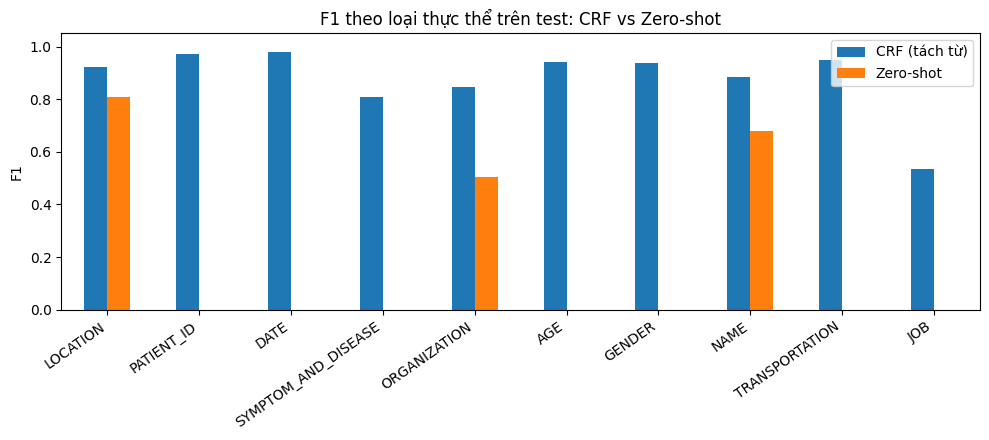

In [52]:
bang_f1_loai[["CRF (tách từ)", "Zero-shot"]].plot(kind="bar", figsize=(10, 4.5))
plt.title("F1 theo loại thực thể trên test: CRF vs Zero-shot")
plt.ylabel("F1")
plt.ylim(0, 1.05)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

In [53]:
# Lưu kết quả để nhóm ghép vào bảng chung với 3 kiến trúc fine-tune
bang_tong_hop.to_csv(os.path.join(KET_QUA_DIR, "baseline_zeroshot_tong_hop.csv"), index=False, encoding="utf-8-sig")
bang_f1_loai.to_csv(os.path.join(KET_QUA_DIR, "baseline_zeroshot_f1_tung_loai.csv"), encoding="utf-8-sig")
loi_crf.to_csv(os.path.join(KET_QUA_DIR, "loi_crf_test.csv"), index=False, encoding="utf-8-sig")
print("Đã lưu các file kết quả vào thư mục", KET_QUA_DIR)

Đã lưu các file kết quả vào thư mục ..\results\phan_tich


Lưu thêm lỗi của zero-shot và dự đoán của cả hai mô hình (để nhóm so sánh với 3 kiến trúc fine-tune ở phần phân tích lỗi chung).

In [54]:
# Lưu thêm kết quả để cả nhóm so sánh lỗi giữa các mô hình (cần chạy xong mục 5 trước)
loi_zs.to_csv(os.path.join(KET_QUA_DIR, "loi_zeroshot_test.csv"), index=False, encoding="utf-8-sig")

du_doan_test = {
    "gold_tach_tu": y_test,                 # nhãn đúng, mức từ
    "gold_am_tiet": test_syl_tags,          # nhãn đúng, mức âm tiết
    "crf_tach_tu": [list(c) for c in y_test_pred_crf],   # CRF trên dữ liệu đã tách từ (ép về list thường vì predict() có thể trả mảng numpy)
    "zero_shot": y_test_pred_zs,            # zero-shot (âm tiết)
}
with open(os.path.join(KET_QUA_DIR, "du_doan_test.json"), "w", encoding="utf-8") as f:
    json.dump(du_doan_test, f, ensure_ascii=False)
print("Đã lưu loi_zeroshot_test.csv và du_doan_test.json vào thư mục", KET_QUA_DIR)

Đã lưu loi_zeroshot_test.csv và du_doan_test.json vào thư mục ..\results\phan_tich


## 6.1 Chấm lại theo chuẩn strict của nhóm và lưu kết quả JSON

Nhóm thống nhất chấm **mọi mô hình** bằng `seqeval` với `mode="strict"` và `scheme=IOB2` (hàm `tinh_metrics` trong `src/metrics.py`) để so sánh công bằng. Các cell trước dùng chế độ **mặc định** của `seqeval`, nên mục này chấm lại và lưu kết quả ra file JSON cho cả nhóm dùng chung. Số sẽ lệch rất ít so với các bảng ở trên.

In [55]:
import sys
sys.path.append("../src")          # Colab: sys.path.append("/content/drive/MyDrive/NLP/src")
from metrics import tinh_metrics, luu_json

THU_MUC_RESULTS = "../results"     # Colab: "/content/drive/MyDrive/NLP/results"

**CRF theo strict.** Chấm `y_test_pred_crf` bằng `tinh_metrics`, ghi kèm tham số đã dùng (`C1_TOT`, `C2_TOT`, 100 vòng lặp) và F1 dev của từng cặp (c1, c2) ở cell 23, rồi lưu `results/crf.json`. Dùng `float()` vì số numpy không lưu được JSON. Lưu ý: F1 dev ở cell 23 được chấm bằng chế độ mặc định, còn F1 test ở đây là strict.

In [56]:
# Bước 1: chấm CRF theo chuẩn strict (ép nhãn về list thường cho chắc)
y_crf_list = [list(c) for c in y_test_pred_crf]
kq_crf_strict = tinh_metrics("CRF (tách từ)", y_test, y_crf_list)

# Bước 2: ghi lại tham số đã dùng
kq_crf_strict["tham_so"] = {
    "c1": float(C1_TOT),
    "c2": float(C2_TOT),
    "max_iterations": 100,
    "muc_du_lieu": "tach_tu",
}

# Bước 3: ghi lại F1 dev của từng cặp (c1, c2) đã thử ở cell 23
# (F1 dev ở cell 23 chấm bằng chế độ mặc định; ép float vì có thể là số numpy)
ket_qua_dev_luu = []
for dong in ket_qua_dev:
    ket_qua_dev_luu.append({"c1": float(dong["c1"]), "c2": float(dong["c2"]), "f1_dev": float(dong["F1_dev"])})
kq_crf_strict["ket_qua_dev"] = ket_qua_dev_luu

# Bước 4: in ra rồi lưu JSON
print("CRF (strict): P =", kq_crf_strict["precision_micro"], "| R =", kq_crf_strict["recall_micro"],
      "| F1 micro =", kq_crf_strict["f1_micro"], "| F1 macro =", kq_crf_strict["f1_macro"])
luu_json(kq_crf_strict, os.path.join(THU_MUC_RESULTS, "crf.json"))
print("Đã lưu results/crf.json")

CRF (strict): P = 0.9375 | R = 0.903 | F1 micro = 0.9199 | F1 macro = 0.8771
Đã lưu results/crf.json


**Zero-shot theo strict.** Chấm `y_test_pred_zs` với nhãn gold mức âm tiết, ghi kèm tên model, bảng ánh xạ nhãn và quy ước "loại model không có thì F1 = 0", rồi lưu `results/zeroshot.json`.

In [57]:
# Bước 1: chấm zero-shot theo chuẩn strict
kq_zs_strict = tinh_metrics("Zero-shot (NER tổng quát)", test_syl_tags, y_test_pred_zs)

# Bước 2: ghi lại model, bảng ánh xạ nhãn và quy ước điểm
kq_zs_strict["tham_so"] = {"model": MODEL_NAME, "muc_du_lieu": "am_tiet"}
kq_zs_strict["bang_anh_xa_nhan"] = {
    "PERSON": "NAME",
    "LOCATION": "LOCATION",
    "ORGANIZATION": "ORGANIZATION",
    "MISCELLANEOUS": "bo",
}
kq_zs_strict["quy_uoc"] = "Loại model không có thì F1 = 0"

# Bước 3: in ra rồi lưu JSON
print("Zero-shot (strict): P =", kq_zs_strict["precision_micro"], "| R =", kq_zs_strict["recall_micro"],
      "| F1 micro =", kq_zs_strict["f1_micro"], "| F1 macro =", kq_zs_strict["f1_macro"])
print("F1 từng loại:", kq_zs_strict["f1_tung_loai"])
luu_json(kq_zs_strict, os.path.join(THU_MUC_RESULTS, "zeroshot.json"))
print("Đã lưu results/zeroshot.json")

Zero-shot (strict): P = 0.6969 | R = 0.3615 | F1 micro = 0.476 | F1 macro = 0.1996
F1 từng loại: {'PATIENT_ID': 0.0, 'NAME': 0.6809, 'AGE': 0.0, 'GENDER': 0.0, 'JOB': 0.0, 'LOCATION': 0.809, 'ORGANIZATION': 0.5057, 'SYMPTOM_AND_DISEASE': 0.0, 'TRANSPORTATION': 0.0, 'DATE': 0.0}
Đã lưu results/zeroshot.json


**Kiểm tra bằng mắt 5 câu đầu của test (zero-shot).** Model trả thực thể theo vị trí **ký tự** (`start`, `end`), còn nhãn gold tính theo **âm tiết**, nên cần xem hàm `chuyen_sang_nhan_BIO` có căn đúng không. Với mỗi câu in: (a) câu gốc, (b) thực thể model tìm được kèm nhãn sau khi đổi, (c) từng âm tiết kèm nhãn BIO rút ra. Nếu vị trí đúng thì các âm tiết của một thực thể sẽ là `B-...` rồi các `I-...` liền nhau.

In [58]:
SO_CAU_KIEM_TRA = 5

for i in range(SO_CAU_KIEM_TRA):
    cac_am_tiet = test_syl[i]
    van_ban = " ".join(cac_am_tiet)
    cac_thuc_the = ner_zero_shot(van_ban)

    print(f"\n--- Câu {i + 1} ---")
    print("(a) Câu gốc:", van_ban)

    print("(b) Thực thể model tìm được:")
    for thuc_the in cac_thuc_the:
        print(f"    word={thuc_the['word']!r} start={thuc_the['start']} end={thuc_the['end']} "
              f"-> nhãn đổi = {doi_nhan(thuc_the['entity_group'])}")

    print("(c) Từng âm tiết kèm nhãn BIO:")
    for am_tiet, nhan in zip(cac_am_tiet, y_test_pred_zs[i]):
        print(f"    {am_tiet:20s} {nhan}")


--- Câu 1 ---
(a) Câu gốc: Từ 24 - 7 đến 31 - 7 , bệnh nhân được mẹ là bà H.T.P ( 47 tuổi ) đón về nhà ở phường Phước Hoà ( bằng xe máy ) , không đi đâu chỉ ra Tạp hoá Phượng , chợ Vườn Lài , phường An Sơn cùng mẹ bán tạp hoá ở đây .
(b) Thực thể model tìm được:
    word='H. T. P' start=47 end=52 -> nhãn đổi = NAME
    word='phường Phước Hoà' start=78 end=94 -> nhãn đổi = LOCATION
    word='Tạp' start=133 end=136 -> nhãn đổi = ORGANIZATION
    word='hoá' start=137 end=140 -> nhãn đổi = LOCATION
    word='Phượng' start=141 end=147 -> nhãn đổi = ORGANIZATION
    word='chợ Vườn Lài' start=150 end=162 -> nhãn đổi = LOCATION
    word='phường An Sơn' start=165 end=178 -> nhãn đổi = LOCATION
(c) Từng âm tiết kèm nhãn BIO:
    Từ                   O
    24                   O
    -                    O
    7                    O
    đến                  O
    31                   O
    -                    O
    7                    O
    ,                    O
    bệnh                 O
    

### Kết quả strict và nhận xét

| Mô hình | Precision | Recall | F1 (micro) | F1 (macro) |
|---|---|---|---|---|
| CRF (tách từ) | 0,9375 | 0,9030 | 0,9199 | 0,8771 |
| Zero-shot | 0,6969 | 0,3615 | 0,4760 | 0,1996 |

**Nhận xét:**
- **CRF đổi rất ít** so với chế độ mặc định (F1 micro 0,9200 → 0,9199), vì chỉ có một vài câu CRF dự đoán nhãn `I-X` mà không có `B-X` đứng trước (kiểm tra trên `du_doan_test.json`: 7 nhãn như vậy trong 7 câu test). Chế độ mặc định coi chỗ đó là một thực thể, chế độ strict thì không.
- **Zero-shot không đổi**, vì nhãn BIO của zero-shot do `chuyen_sang_nhan_BIO` tạo ra luôn bắt đầu bằng `B-` nên không có nhãn lỗi kiểu này.
- Số F1 dev trong `results/crf.json` lấy từ cell 23 (chế độ mặc định); số test là strict.

**Câu hỏi vấn đáp:**
1. *Strict khác chế độ mặc định của seqeval ở đâu?* Mặc định vẫn coi `I-X` đứng sau `O` là bắt đầu một thực thể; strict + IOB2 không tính nhãn lỗi đó là thực thể.
2. *Vì sao phải chấm lại bằng strict khi đã có số ở các mục trên?* Cả nhóm thống nhất một cách chấm cho mọi mô hình để so sánh công bằng; số cũ dùng chế độ mặc định.
3. *Vì sao số CRF lệch rất ít?* Chỉ có vài nhãn `I-` mồ côi trong dự đoán của CRF; hầu hết thực thể đều có `B-` đứng đầu nên hai cách chấm cho cùng kết quả.
4. *Vì sao loại model không có thì F1 = 0?* Model không dự đoán loại đó nên không đúng thực thể nào (Recall = 0); dùng `zero_division=0` để F1 ghi là 0 thay vì lỗi chia cho 0.

## 7. Tóm tắt tiền xử lý và tham số đã dùng

**Tiền xử lý**
- Dữ liệu mức **từ** (`data/word`, đã tách từ sẵn bằng RDRSegmenter của VnCoreNLP): dùng để train và đánh giá CRF chính.
- Dữ liệu mức **âm tiết** (`data/syllable`): dùng cho zero-shot (ghép âm tiết thành câu thô rồi đưa vào model).
- `underthesea.word_tokenize`: chỉ dùng cho văn bản mới (mục 3.5), vì tách từ khác dataset ở khá nhiều câu (mục 2).
- Nhãn theo định dạng BIO, giữ nguyên, không chỉnh sửa gì thêm.

**(A) CRF (`sklearn-crfsuite`)**

| Hạng mục | Giá trị |
|---|---|
| Thuật toán | L-BFGS, tối đa 100 vòng lặp, `all_possible_transitions=True` |
| `(c1, c2)` | Thử 4 cặp (0,1; 0,1), (0,05; 0,05), (0,3; 0,05), (0,01; 0,01) trên dev, chọn (0,05; 0,05) với F1 dev = 0,9246 |
| Đặc trưng của từ hiện tại | từ (chữ thường), hình dạng, viết hoa chữ đầu / viết hoa toàn bộ / là số, là từ ghép (có `_`), tiền tố và hậu tố 3 ký tự, âm tiết đầu và âm tiết cuối |
| Đặc trưng ngữ cảnh | từ liền trước và liền sau (±1): từ chữ thường, viết hoa chữ đầu, là số, hình dạng, bigram với từ hiện tại; từ cách 2 vị trí (±2): chỉ có từ chữ thường; cờ đầu câu, cuối câu |
| Quy trình | Train trên train, chọn siêu tham số trên dev, đánh giá trên test đúng 1 lần |

**(B) Zero-shot**

| Hạng mục | Giá trị |
|---|---|
| Model | `NlpHUST/ner-vietnamese-electra-base` (fine-tune trên VLSP 2018, nhãn: PERSON, LOCATION, ORGANIZATION, MISCELLANEOUS) |
| Cách gọi | `pipeline("token-classification", aggregation_strategy="simple")`, không train lại |
| Ánh xạ nhãn | PERSON → NAME, LOCATION → LOCATION, ORGANIZATION → ORGANIZATION; MISCELLANEOUS bỏ; 7 loại còn lại model không dự đoán được |
| Dữ liệu | Tập test mức âm tiết (3000 câu), ghép bằng dấu cách; vị trí ký tự của thực thể được đổi lại thành nhãn BIO cho từng âm tiết |

**Đánh giá chung:** `seqeval` mức thực thể (đúng cả loại và ranh giới): Precision / Recall / F1 micro và macro, F1 từng loại; phân loại lỗi thành 5 nhóm (bỏ sót, sai biên, sai loại, sai cả biên và loại, dự đoán thừa). Ở mục 6.1, kết quả được chấm lại bằng `seqeval` chế độ `strict` với `scheme=IOB2` (hàm `tinh_metrics` trong `src/metrics.py`) theo quy ước chung của nhóm; hai cách chấm chênh nhau dưới 0,001.

**Phân công:** phần (A), (B), tiền xử lý tách từ và phân tích lỗi của hai phần này do Phúc phụ trách; phần (C) fine-tune các kiến trúc pretrained và demo do ba bạn còn lại phụ trách.

## 8. Kết luận và ghi chú vấn đáp

### Kết luận
- **CRF** với đặc trưng thủ công là baseline khá mạnh vì nhiều thực thể lặp lại giữa train và test (mã bệnh nhân, ngày, giới tính, tuổi có mẫu rất rõ). Điểm yếu nằm ở `JOB`, `SYMPTOM_AND_DISEASE`, `ORGANIZATION` — các cụm đa dạng hoặc phụ thuộc ngữ cảnh rộng.
- **So với bài báo gốc** (chỉ để tham chiếu, không phải so sánh chặt: bài báo báo cáo trung bình 5 lần chạy của BiLSTM-CNN-CRF, còn CRF của nhóm chạy một lần): CRF của nhóm đạt F1 micro 0,920 trên dữ liệu mức từ, cao hơn khoảng 0,01 so với 0,910 của BiLSTM-CNN-CRF mức từ trong bài báo.
- **Zero-shot** với model NER tổng quát **yếu hơn rất nhiều**, đúng như đề bài dự kiến:
  1. Model chỉ biết 3 loại chung → 7/10 loại đặc thù có F1 = 0; kể cả đoán đúng 100% 3 loại chung thì F1 vẫn bị chặn ở mức "trần lý thuyết" (mục 5.2).
  2. Ngay cả ở 3 loại chung, **quy tắc gán nhãn khác nhau**: PhoNER_COVID19 chỉ gán thực thể liên quan tới bệnh nhân (không gán người phát ngôn, cơ quan báo chí, quốc tịch), tách địa chỉ thành từng cấp... nên model tổng quát bị nhiều lỗi "dự đoán thừa" và "sai biên".

### Câu hỏi vấn đáp có thể gặp
**1. CRF khác Logistic Regression phân loại từng từ ở điểm nào?**
CRF tối ưu xác suất của **cả chuỗi nhãn**, học thêm trọng số chuyển nhãn (transition), trong đó các chuyển nhãn vô lý như `O → I-LOCATION` có trọng số rất âm nên gần như không xảy ra (đây là điểm số đã học, không phải ràng buộc cứng). Phân loại từng từ thì mỗi từ được quyết định độc lập.

**2. `c1`, `c2` là gì?** Hệ số regularization L1 và L2, chống overfit. Chọn bằng tập dev, không chọn bằng test.

**3. Vì sao dùng `seqeval` mà không dùng accuracy theo từ?** Khoảng 74–79% nhãn là `O` (train 79,1%, dev 74,9%, test 74,2%), nên accuracy theo từ luôn rất cao dù model bỏ sót nhiều thực thể. `seqeval` tính theo **thực thể** và chỉ tính đúng khi khớp cả loại lẫn ranh giới.

**4. Micro-F1 và macro-F1 khác nhau thế nào?** Micro gộp tất cả thực thể rồi tính → bị chi phối bởi loại nhiều (LOCATION, PATIENT_ID). Macro tính F1 từng loại rồi lấy trung bình → phản ánh cả các loại hiếm (JOB, TRANSPORTATION).

**5. Vì sao zero-shot gần như chắc chắn thua CRF?** CRF được học trên chính dữ liệu và bộ nhãn của PhoNER_COVID19; model zero-shot không biết 7/10 loại nhãn và theo quy tắc gán nhãn khác.

**6. Tách từ có giúp NER không?** Theo bài báo gốc thì có: BiLSTM-CNN-CRF tăng từ 0,906 lên 0,910 (micro-F1) và từ 0,858 lên 0,875 (macro-F1) khi dùng dữ liệu đã tách từ. Về lý do, đặc trưng mức từ (`bệnh_viện`) mang nghĩa rõ hơn từng âm tiết (`bệnh`, `viện`), và với PhoBERT còn do model được pretrain trên văn bản đã tách từ. Notebook này dùng bản tách từ sẵn của dataset nên không tự đo riêng cho CRF; phép so sánh có/không tách từ với PhoBERT nằm ở phần yêu cầu nâng cao.

**7. Vì sao không tự tách từ lại bằng underthesea để train?** Dataset đã tách từ sẵn (VnCoreNLP) và nhãn khớp với từng từ. underthesea tách khác ở khá nhiều câu (mục 2), nếu dùng thì phải căn lại nhãn, dễ làm lệch ranh giới thực thể. underthesea được dùng cho văn bản mới nhập vào (mục 3.5).

### Hạn chế
- **Zero-shot chỉ dùng 1 model** và chỉ ánh xạ được 3/10 nhãn (NAME, LOCATION, ORGANIZATION).
- **CRF chạy một lần**: thuật toán L-BFGS không ngẫu nhiên nên không cần nhiều seed, nhưng cũng nghĩa là chưa có độ lệch chuẩn.
- **Chọn siêu tham số còn hẹp**: chỉ thử 4 cặp (c1, c2) trên dev.
- **So sánh CRF và zero-shot khác mức token** (từ và âm tiết). Số thực thể ở hai phiên bản bằng nhau (cột support trong báo cáo zero-shot ở mục 5 trùng với số thực thể ở mục 1, tổng 11735 trên test) nên F1 theo thực thể vẫn so sánh được.
